In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sleep = pd.read_csv("../data/raw/sleep_diary.csv")
hrv = pd.read_csv("../data/raw/sensor_hrv_filtered.csv")

In [2]:
print("Sleep shape:", sleep.shape)
print("HRV shape:", hrv.shape)

display(sleep.head())
display(hrv.head())

Sleep shape: (1372, 11)
HRV shape: (38913, 28)


,userId,date,go2bed,asleep,wakeup,wakeup@night,waso,sleep_duration,in_bed_duration,sleep_latency,sleep_efficiency
0,pm96,2021-03-09,01:00:00,02:00:00,08:30:00,0,0.0,6.500000,7.500000,1.000000,0.866667
1,pm96,2021-03-10,00:00:00,00:40:00,07:50:00,0,0.0,7.166667,7.833333,0.666667,0.914894
2,pm96,2021-03-11,00:30:00,01:00:00,07:40:00,0,0.0,6.666667,7.166667,0.500000,0.930233
3,pm96,2021-03-12,00:30:00,01:00:00,07:50:00,0,0.0,6.833333,7.333333,0.500000,0.931818
4,pm96,2021-03-13,01:00:00,01:30:00,10:30:00,0,0.0,9.000000,9.500000,0.500000,0.947368


,deviceId,ts_start,ts_end,missingness_score,HR,ibi,acc_x_avg,acc_y_avg,acc_z_avg,grv_x_avg,...,calories,light_avg,sdnn,sdsd,rmssd,pnn20,pnn50,lf,hf,lf/hf
0,ab60,1617262425031,1617262724833,0.295448,84.592816,728.534374,0.284765,-0.593973,9.195984,-0.094203,...,0.000000,841.324415,89.363225,78.033038,98.417649,0.746269,0.391791,1818.065625,1252.992443,1.450979
1,ab60,1616736817151,1616737116986,0.239085,78.589565,781.896913,3.050179,-1.239353,5.790543,-0.211973,...,0.085083,486.485050,100.804974,73.468687,106.602933,0.803704,0.540741,1918.499169,2784.393293,0.689019
2,ab60,1616736517083,1616736816952,0.100773,75.620524,812.183910,2.153267,-3.546833,8.499866,-0.628970,...,NaN,779.033113,89.073518,48.675496,74.504896,0.809816,0.484663,1292.696555,1034.550027,1.249525
3,ab60,1616736217077,1616736516883,0.268178,85.813165,769.754943,2.898409,-3.401356,4.606113,-0.249247,...,1.375000,389.408638,102.371770,48.631219,70.615187,0.719178,0.400685,1561.785747,812.118619,1.923101
4,ab60,1616734416800,1616734716672,0.043466,76.944500,775.190053,-0.050221,-6.576164,5.377019,0.715893,...,0.000000,276.345515,84.045665,42.104491,66.973170,0.736111,0.450000,3460.217895,1886.157661,1.834533


In [3]:
print(hrv.columns.tolist())


['deviceId', 'ts_start', 'ts_end', 'missingness_score', 'HR', 'ibi', 'acc_x_avg', 'acc_y_avg', 'acc_z_avg', 'grv_x_avg', 'grv_y_avg', 'grv_z_avg', 'grv_w_avg', 'gyr_x_avg', 'gyr_y_avg', 'gyr_z_avg', 'steps', 'distance', 'calories', 'light_avg', 'sdnn', 'sdsd', 'rmssd', 'pnn20', 'pnn50', 'lf', 'hf', 'lf/hf']


In [4]:
print(hrv[['deviceId', 'ts_start', 'ts_end', 'rmssd']].head(10))
print()
print(hrv[['deviceId', 'ts_start', 'ts_end', 'rmssd']].dtypes)

  deviceId       ts_start         ts_end       rmssd
0     ab60  1617262425031  1617262724833   98.417649
1     ab60  1616736817151  1616737116986  106.602933
2     ab60  1616736517083  1616736816952   74.504896
3     ab60  1616736217077  1616736516883   70.615187
4     ab60  1616734416800  1616734716672   66.973170
5     ab60  1616733816674  1616734116540   74.112096
6     ab60  1616733516611  1616733816474   73.054342
7     ab60  1616733216540  1616733516412   71.231679
8     ab60  1616732916461  1616733216340  110.489949
9     ab60  1616731716199  1616732016090   72.165157

deviceId        str
ts_start      int64
ts_end        int64
rmssd       float64
dtype: object


In [5]:
print("Unique sleep users:", sleep['userId'].nunique())
print("Unique HRV devices:", hrv['deviceId'].nunique())

print("\nSleep users sample:")
print(sleep['userId'].unique()[:10])

print("\nHRV devices sample:")
print(hrv['deviceId'].unique()[:10])

Unique sleep users: 49
Unique HRV devices: 49

Sleep users sample:
<StringArray>
['pm96', 'vc10', 'pg18', 'nd56', 'vs14', 'gm49', 'wc58', 'hp91', 'ba30',
 'mh40']
Length: 10, dtype: str

HRV devices sample:
<StringArray>
['ab60', 'am77', 'av54', 'ba30', 'bp16', 'br74', 'ca37', 'dk68', 'ea80',
 'ej27']
Length: 10, dtype: str


In [6]:
survey = pd.read_csv("../data/raw/survey.csv")

print("Survey shape:", survey.shape)
print(survey.columns.tolist())

display(survey.head(10))


Survey shape: (49, 23)
['deviceId', 'sex', 'age', 'marriage', 'occupation', 'smartwatch', 'regular', 'exercise', 'coffee', 'smoking', 'drinking', 'height', 'weight', 'ISI_1', 'PHQ9_1', 'GAD7_1', 'MEQ', 'ISI_2', 'PHQ9_2', 'GAD7_2', 'ISI_F', 'PHQ9_F', 'GAD7_F']


,deviceId,sex,age,marriage,occupation,smartwatch,regular,exercise,coffee,smoking,...,ISI_1,PHQ9_1,GAD7_1,MEQ,ISI_2,PHQ9_2,GAD7_2,ISI_F,PHQ9_F,GAD7_F
0,pm96,1,36,1,3,1,3,5,4,1,...,8,1,1,46,7.0,1.0,0.0,9.0,0.0,0.0
1,vc10,2,31,1,3,2,2,5,2,1,...,11,3,1,28,17.0,4.0,0.0,8.0,1.0,0.0
2,pg18,2,38,1,3,1,3,3,3,1,...,10,5,2,48,12.0,3.0,1.0,10.0,5.0,4.0
3,nd56,2,40,3,2,1,4,4,5,1,...,8,3,0,55,10.0,6.0,0.0,9.0,4.0,0.0
4,vs14,2,28,1,2,2,4,2,2,1,...,14,10,8,35,14.0,12.0,11.0,13.0,11.0,6.0
5,gm49,2,25,1,2,2,3,3,3,1,...,10,6,10,40,7.0,6.0,8.0,6.0,4.0,3.0
6,wc58,1,34,1,2,1,4,3,5,1,...,8,9,7,42,9.0,8.0,6.0,14.0,9.0,7.0
7,hp91,2,23,1,1,2,2,3,1,1,...,6,1,0,37,8.0,1.0,0.0,8.0,2.0,1.0
8,ba30,1,27,1,2,1,2,1,4,1,...,8,1,2,62,8.0,7.0,2.0,3.0,1.0,0.0
9,mh40,1,24,1,1,2,2,2,1,1,...,10,3,0,48,4.0,2.0,0.0,8.0,4.0,0.0


In [7]:
sleep_ids = set(sleep["userId"].unique())
hrv_ids = set(hrv["deviceId"].unique())
survey_ids = set(survey["deviceId"].unique())

print("Sleep x Survey:", len(sleep_ids & survey_ids))
print("Sleep x HRV:", len(sleep_ids & hrv_ids))
print("Survey x HRV:", len(survey_ids & hrv_ids))

print("\nIDs shared between sleep and HRV:")
print(sorted(sleep_ids & hrv_ids))

Sleep x Survey: 49
Sleep x HRV: 49
Survey x HRV: 49

IDs shared between sleep and HRV:
['ab60', 'am77', 'av54', 'ba30', 'bp16', 'br74', 'ca37', 'dk68', 'ea80', 'ej27', 'ev76', 'ga64', 'gd81', 'gm49', 'gw39', 'gw57', 'hk52', 'hp91', 'it48', 'ka67', 'kb24', 'kn13', 'md23', 'mg25', 'mh40', 'nd56', 'pg18', 'pm96', 'pw85', 'rb86', 'rw83', 'ry23', 'sc27', 'sh29', 'sm34', 'sp33', 'te43', 'ub12', 'us73', 'uz94', 'vc10', 'vh17', 'vs14', 'wc58', 'we59', 'xp20', 'xw99', 'ya71', 'zk41']


In [8]:
hrv["datetime"] = pd.to_datetime(
    hrv["ts_start"],
    unit="ms"
)

hrv[["deviceId", "ts_start", "datetime", "rmssd"]].head(10)

,deviceId,ts_start,datetime,rmssd
0,ab60,1617262425031,2021-04-01 07:33:45.031,98.417649
1,ab60,1616736817151,2021-03-26 05:33:37.151,106.602933
2,ab60,1616736517083,2021-03-26 05:28:37.083,74.504896
3,ab60,1616736217077,2021-03-26 05:23:37.077,70.615187
4,ab60,1616734416800,2021-03-26 04:53:36.800,66.973170
5,ab60,1616733816674,2021-03-26 04:43:36.674,74.112096
6,ab60,1616733516611,2021-03-26 04:38:36.611,73.054342
7,ab60,1616733216540,2021-03-26 04:33:36.540,71.231679
8,ab60,1616732916461,2021-03-26 04:28:36.461,110.489949
9,ab60,1616731716199,2021-03-26 04:08:36.199,72.165157


In [9]:
print("HRV min:", hrv["datetime"].min())
print("HRV max:", hrv["datetime"].max())

print("Sleep min:", sleep["date"].min())
print("Sleep max:", sleep["date"].max())

HRV min: 2018-01-01 20:17:11.436000
HRV max: 2021-04-08 03:09:51.127000
Sleep min: 2021-03-09
Sleep max: 2021-04-05


In [10]:
hrv["year"] = hrv["datetime"].dt.year

print(hrv["year"].value_counts().sort_index())

year
2018        1
2021    38912
Name: count, dtype: int64


In [11]:
print(
    hrv.loc[hrv["datetime"] < "2021-03-01", "deviceId"]
    .value_counts()
    .head(20)
)

deviceId
sm34    1
Name: count, dtype: int64


In [12]:
hrv_analysis = hrv[
    (hrv["datetime"] >= "2021-03-09") &
    (hrv["datetime"] <= "2021-04-06")
].copy()

print("Filtered HRV shape:", hrv_analysis.shape)
print("Filtered HRV min:", hrv_analysis["datetime"].min())
print("Filtered HRV max:", hrv_analysis["datetime"].max())

Filtered HRV shape: (35322, 30)
Filtered HRV min: 2021-03-09 00:01:00.585000
Filtered HRV max: 2021-04-05 16:03:53.768000


In [13]:
hrv_analysis["hour"] = hrv_analysis["datetime"].dt.hour

print(
    hrv_analysis["hour"]
    .value_counts()
    .sort_index()
)

hour
0     1610
1     1957
2     2014
3     1951
4     2262
5     2417
6     2518
7     2427
8     2010
9     1717
10    1843
11    2031
12    2200
13    2055
14    1742
15    1391
16     866
17     506
18     202
19     152
20     142
21     149
22     299
23     861
Name: count, dtype: int64


In [14]:
morning_hrv = hrv_analysis[
    hrv_analysis["hour"].between(6, 10)
].copy()

morning_hrv["date"] = morning_hrv["datetime"].dt.date

print("Morning HRV rows:", morning_hrv.shape[0])
print("Participants:", morning_hrv["deviceId"].nunique())
print("Participant-days:",
      morning_hrv[["deviceId", "date"]].drop_duplicates().shape[0])

Morning HRV rows: 10515
Participants: 49
Participant-days: 991


In [15]:
windows_per_day = (
    morning_hrv
    .groupby(["deviceId", "date"])
    .size()
)

print(windows_per_day.describe())

count    991.000000
mean      10.610494
std       10.377601
min        1.000000
25%        3.000000
50%        7.000000
75%       15.000000
max       57.000000
dtype: float64


In [16]:
for threshold in [1, 3, 5, 10]:
    valid_days = (windows_per_day >= threshold).sum()
    print(
        f"At least {threshold} windows: "
        f"{valid_days} participant-days "
        f"({valid_days / len(windows_per_day):.1%})"
    )

At least 1 windows: 991 participant-days (100.0%)
At least 3 windows: 766 participant-days (77.3%)
At least 5 windows: 633 participant-days (63.9%)
At least 10 windows: 397 participant-days (40.1%)


In [17]:
print(morning_hrv["rmssd"].describe())

count    10515.000000
mean        78.572354
std         29.654406
min         10.878642
25%         58.359530
50%         74.908546
75%         93.322992
max        281.926898
Name: rmssd, dtype: float64


In [18]:
print(
    morning_hrv["rmssd"]
    .quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
)

0.01     29.022640
0.05     38.808364
0.25     58.359530
0.50     74.908546
0.75     93.322992
0.95    128.728456
0.99    181.543503
Name: rmssd, dtype: float64


In [19]:
morning_daily = (
    morning_hrv
    .groupby(["deviceId", "date"])
    .agg(
        morning_rmssd=("rmssd", "median"),
        n_windows=("rmssd", "size")
    )
    .reset_index()
)

morning_daily = morning_daily[
    morning_daily["n_windows"] >= 3
].copy()

print("Valid participant-days:", morning_daily.shape[0])

display(morning_daily.head(10))

Valid participant-days: 766


,deviceId,date,morning_rmssd,n_windows
0,ab60,2021-03-09,51.386841,8
1,ab60,2021-03-10,56.378000,6
2,ab60,2021-03-11,84.275451,19
3,ab60,2021-03-12,79.579542,4
4,ab60,2021-03-13,77.364504,10
5,ab60,2021-03-14,63.464005,34
6,ab60,2021-03-15,83.206794,8
7,ab60,2021-03-16,74.196858,17
8,ab60,2021-03-17,76.443466,11
9,ab60,2021-03-18,68.387785,8


In [20]:
sleep_analysis = sleep.copy()

sleep_analysis["date"] = pd.to_datetime(
    sleep_analysis["date"]
).dt.date

sleep_analysis = sleep_analysis[
    [
        "userId",
        "date",
        "sleep_duration",
        "sleep_efficiency",
        "waso",
        "sleep_latency"
    ]
].copy()

display(sleep_analysis.head())

,userId,date,sleep_duration,sleep_efficiency,waso,sleep_latency
0,pm96,2021-03-09,6.500000,0.866667,0.0,1.000000
1,pm96,2021-03-10,7.166667,0.914894,0.0,0.666667
2,pm96,2021-03-11,6.666667,0.930233,0.0,0.500000
3,pm96,2021-03-12,6.833333,0.931818,0.0,0.500000
4,pm96,2021-03-13,9.000000,0.947368,0.0,0.500000


In [21]:
analysis_df = sleep_analysis.merge(
    morning_daily,
    left_on=["userId", "date"],
    right_on=["deviceId", "date"],
    how="inner"
)

analysis_df = analysis_df.drop(columns="deviceId")

print("Final dataset shape:", analysis_df.shape)
print("Participants:", analysis_df["userId"].nunique())

display(analysis_df.head(10))

Final dataset shape: (766, 8)
Participants: 49


,userId,date,sleep_duration,sleep_efficiency,waso,sleep_latency,morning_rmssd,n_windows
0,pm96,2021-03-09,6.500000,0.866667,0.0,1.000000,83.279344,13
1,pm96,2021-03-10,7.166667,0.914894,0.0,0.666667,79.604133,23
2,pm96,2021-03-11,6.666667,0.930233,0.0,0.500000,73.007175,6
3,pm96,2021-03-12,6.833333,0.931818,0.0,0.500000,64.435499,41
4,pm96,2021-03-13,9.000000,0.947368,0.0,0.500000,82.416923,10
5,pm96,2021-03-14,8.666667,0.945455,0.0,0.500000,92.966694,24
6,pm96,2021-03-15,5.500000,0.846154,0.0,1.000000,75.108388,3
7,pm96,2021-03-16,6.000000,0.923077,0.0,0.500000,94.828757,5
8,pm96,2021-03-17,5.666667,0.918919,0.0,0.500000,44.639625,4
9,pm96,2021-03-18,6.666667,0.930233,0.0,0.500000,84.992133,5


In [22]:
sleep_timing = sleep.copy()

sleep_timing["date"] = pd.to_datetime(sleep_timing["date"])

sleep_timing["wakeup_datetime"] = pd.to_datetime(
    sleep_timing["date"].astype(str) + " " + sleep_timing["wakeup"].astype(str)
)

display(
    sleep_timing[
        ["userId", "date", "wakeup", "wakeup_datetime"]
    ].head(10)
)

,userId,date,wakeup,wakeup_datetime
0,pm96,2021-03-09,08:30:00,2021-03-09 08:30:00
1,pm96,2021-03-10,07:50:00,2021-03-10 07:50:00
2,pm96,2021-03-11,07:40:00,2021-03-11 07:40:00
3,pm96,2021-03-12,07:50:00,2021-03-12 07:50:00
4,pm96,2021-03-13,10:30:00,2021-03-13 10:30:00
5,pm96,2021-03-14,10:10:00,2021-03-14 10:10:00
6,pm96,2021-03-15,07:30:00,2021-03-15 07:30:00
7,pm96,2021-03-16,07:30:00,2021-03-16 07:30:00
8,pm96,2021-03-17,07:40:00,2021-03-17 07:40:00
9,pm96,2021-03-18,07:40:00,2021-03-18 07:40:00


In [23]:
sleep_timing["hrv_window_end"] = (
    sleep_timing["wakeup_datetime"] + pd.Timedelta(hours=2)
)

display(
    sleep_timing[
        [
            "userId",
            "wakeup_datetime",
            "hrv_window_end"
        ]
    ].head(10)
)

,userId,wakeup_datetime,hrv_window_end
0,pm96,2021-03-09 08:30:00,2021-03-09 10:30:00
1,pm96,2021-03-10 07:50:00,2021-03-10 09:50:00
2,pm96,2021-03-11 07:40:00,2021-03-11 09:40:00
3,pm96,2021-03-12 07:50:00,2021-03-12 09:50:00
4,pm96,2021-03-13 10:30:00,2021-03-13 12:30:00
5,pm96,2021-03-14 10:10:00,2021-03-14 12:10:00
6,pm96,2021-03-15 07:30:00,2021-03-15 09:30:00
7,pm96,2021-03-16 07:30:00,2021-03-16 09:30:00
8,pm96,2021-03-17 07:40:00,2021-03-17 09:40:00
9,pm96,2021-03-18 07:40:00,2021-03-18 09:40:00


In [24]:
hrv_analysis["date"] = hrv_analysis["datetime"].dt.date

sleep_timing["merge_date"] = sleep_timing["wakeup_datetime"].dt.date

print(hrv_analysis[["deviceId", "datetime", "date"]].head())
print()
print(sleep_timing[["userId", "wakeup_datetime", "merge_date"]].head())

  deviceId                datetime        date
0     ab60 2021-04-01 07:33:45.031  2021-04-01
1     ab60 2021-03-26 05:33:37.151  2021-03-26
2     ab60 2021-03-26 05:28:37.083  2021-03-26
3     ab60 2021-03-26 05:23:37.077  2021-03-26
4     ab60 2021-03-26 04:53:36.800  2021-03-26

  userId     wakeup_datetime  merge_date
0   pm96 2021-03-09 08:30:00  2021-03-09
1   pm96 2021-03-10 07:50:00  2021-03-10
2   pm96 2021-03-11 07:40:00  2021-03-11
3   pm96 2021-03-12 07:50:00  2021-03-12
4   pm96 2021-03-13 10:30:00  2021-03-13


In [25]:
post_wakeup_hrv = hrv_analysis.merge(
    sleep_timing[
        [
            "userId",
            "merge_date",
            "wakeup_datetime",
            "hrv_window_end",
            "sleep_duration",
            "sleep_efficiency",
            "waso",
            "sleep_latency"
        ]
    ],
    left_on=["deviceId", "date"],
    right_on=["userId", "merge_date"],
    how="inner"
)

print("Rows after merge:", post_wakeup_hrv.shape[0])

display(
    post_wakeup_hrv[
        [
            "deviceId",
            "datetime",
            "wakeup_datetime",
            "hrv_window_end",
            "rmssd"
        ]
    ].head(10)
)

Rows after merge: 35322


,deviceId,datetime,wakeup_datetime,hrv_window_end,rmssd
0,ab60,2021-04-01 07:33:45.031,2021-04-01 08:30:00,2021-04-01 10:30:00,98.417649
1,ab60,2021-03-26 05:33:37.151,2021-03-26 10:00:00,2021-03-26 12:00:00,106.602933
2,ab60,2021-03-26 05:28:37.083,2021-03-26 10:00:00,2021-03-26 12:00:00,74.504896
3,ab60,2021-03-26 05:23:37.077,2021-03-26 10:00:00,2021-03-26 12:00:00,70.615187
4,ab60,2021-03-26 04:53:36.800,2021-03-26 10:00:00,2021-03-26 12:00:00,66.973170
5,ab60,2021-03-26 04:43:36.674,2021-03-26 10:00:00,2021-03-26 12:00:00,74.112096
6,ab60,2021-03-26 04:38:36.611,2021-03-26 10:00:00,2021-03-26 12:00:00,73.054342
7,ab60,2021-03-26 04:33:36.540,2021-03-26 10:00:00,2021-03-26 12:00:00,71.231679
8,ab60,2021-03-26 04:28:36.461,2021-03-26 10:00:00,2021-03-26 12:00:00,110.489949
9,ab60,2021-03-26 04:08:36.199,2021-03-26 10:00:00,2021-03-26 12:00:00,72.165157


In [26]:
post_wakeup_hrv = post_wakeup_hrv[
    (post_wakeup_hrv["datetime"] >= post_wakeup_hrv["wakeup_datetime"]) &
    (post_wakeup_hrv["datetime"] <= post_wakeup_hrv["hrv_window_end"])
].copy()

print("Rows inside 2-hour post-wakeup window:", post_wakeup_hrv.shape[0])

display(
    post_wakeup_hrv[
        [
            "deviceId",
            "datetime",
            "wakeup_datetime",
            "hrv_window_end",
            "rmssd"
        ]
    ].head(10)
)

Rows inside 2-hour post-wakeup window: 3940


,deviceId,datetime,wakeup_datetime,hrv_window_end,rmssd
16,ab60,2021-03-26 10:09:18.233,2021-03-26 10:00:00,2021-03-26 12:00:00,51.054606
48,ab60,2021-03-26 10:24:18.418,2021-03-26 10:00:00,2021-03-26 12:00:00,91.908089
49,ab60,2021-03-25 11:35:21.074,2021-03-25 10:00:00,2021-03-25 12:00:00,66.567055
57,ab60,2021-03-25 11:30:21.031,2021-03-25 10:00:00,2021-03-25 12:00:00,61.813215
65,ab60,2021-03-25 11:55:21.224,2021-03-25 10:00:00,2021-03-25 12:00:00,70.959328
66,ab60,2021-03-25 11:50:21.217,2021-03-25 10:00:00,2021-03-25 12:00:00,62.950661
67,ab60,2021-03-25 11:45:21.119,2021-03-25 10:00:00,2021-03-25 12:00:00,78.794197
68,ab60,2021-03-25 11:40:21.092,2021-03-25 10:00:00,2021-03-25 12:00:00,81.390683
70,ab60,2021-03-26 10:44:18.698,2021-03-26 10:00:00,2021-03-26 12:00:00,88.321232
71,ab60,2021-03-26 11:19:19.375,2021-03-26 10:00:00,2021-03-26 12:00:00,82.456159


In [27]:
post_wakeup_windows = (
    post_wakeup_hrv
    .groupby(["deviceId", "merge_date"])
    .size()
)

print(post_wakeup_windows.describe())

count    742.000000
mean       5.309973
std        4.439533
min        1.000000
25%        2.000000
50%        4.000000
75%        8.000000
max       24.000000
dtype: float64


In [28]:
for threshold in [1, 3, 5, 10]:
    valid_days = (post_wakeup_windows >= threshold).sum()

    print(
        f"At least {threshold} windows: "
        f"{valid_days} participant-days "
        f"({valid_days / len(post_wakeup_windows):.1%})"
    )

At least 1 windows: 742 participant-days (100.0%)
At least 3 windows: 495 participant-days (66.7%)
At least 5 windows: 333 participant-days (44.9%)
At least 10 windows: 124 participant-days (16.7%)


In [29]:
post_wakeup_daily = (
    post_wakeup_hrv
    .groupby(["deviceId", "merge_date"])
    .agg(
        post_wakeup_rmssd=("rmssd", "median"),
        n_windows=("rmssd", "size")
    )
    .reset_index()
)

post_wakeup_daily = post_wakeup_daily[
    post_wakeup_daily["n_windows"] >= 3
].copy()

print("Valid participant-days:", post_wakeup_daily.shape[0])

display(post_wakeup_daily.head(10))

Valid participant-days: 495


,deviceId,merge_date,post_wakeup_rmssd,n_windows
0,ab60,2021-03-09,47.067920,12
2,ab60,2021-03-11,72.682372,7
3,ab60,2021-03-14,53.266921,9
4,ab60,2021-03-15,96.176078,11
5,ab60,2021-03-16,70.002278,12
6,ab60,2021-03-17,73.534199,10
7,ab60,2021-03-18,71.096710,5
8,ab60,2021-03-19,63.564907,10
9,ab60,2021-03-20,68.392292,11
10,ab60,2021-03-21,69.061438,3


In [30]:
analysis_df = sleep_timing.merge(
    post_wakeup_daily,
    left_on=["userId", "merge_date"],
    right_on=["deviceId", "merge_date"],
    how="inner"
)

analysis_df = analysis_df.drop(columns="deviceId")

print("Final dataset shape:", analysis_df.shape)
print("Participants:", analysis_df["userId"].nunique())

display(
    analysis_df[
        [
            "userId",
            "merge_date",
            "sleep_duration",
            "sleep_efficiency",
            "waso",
            "sleep_latency",
            "post_wakeup_rmssd",
            "n_windows"
        ]
    ].head(10)
)

Final dataset shape: (495, 16)
Participants: 47


,userId,merge_date,sleep_duration,sleep_efficiency,waso,sleep_latency,post_wakeup_rmssd,n_windows
0,pm96,2021-03-09,6.500000,0.866667,0.0,1.000000,83.279344,5
1,pm96,2021-03-10,7.166667,0.914894,0.0,0.666667,102.516604,8
2,pm96,2021-03-12,6.833333,0.931818,0.0,0.500000,72.716830,20
3,pm96,2021-03-14,8.666667,0.945455,0.0,0.500000,82.701464,5
4,pm96,2021-03-16,6.000000,0.923077,0.0,0.500000,84.902119,4
5,pm96,2021-03-17,5.666667,0.918919,0.0,0.500000,44.951305,3
6,pm96,2021-03-19,6.166667,0.925000,0.0,0.500000,74.320820,4
7,pm96,2021-03-20,7.833333,0.940000,0.0,0.500000,77.129084,15
8,pm96,2021-03-21,8.000000,0.941176,0.0,0.500000,61.598708,14
9,pm96,2021-03-23,6.000000,0.923077,30.0,0.500000,49.732285,4


In [31]:
analysis_variables = [
    "sleep_duration",
    "sleep_efficiency",
    "waso",
    "sleep_latency",
    "post_wakeup_rmssd",
    "n_windows"
]

print("Missing values:")
print(analysis_df[analysis_variables].isna().sum())

print("\nDescriptive statistics:")
display(
    analysis_df[analysis_variables].describe()
)

Missing values:
sleep_duration       0
sleep_efficiency     0
waso                 2
sleep_latency        0
post_wakeup_rmssd    0
n_windows            0
dtype: int64

Descriptive statistics:


,sleep_duration,sleep_efficiency,waso,sleep_latency,post_wakeup_rmssd,n_windows
count,495.000000,495.000000,493.000000,495.000000,495.000000,495.000000
mean,7.751717,0.938204,12.541582,0.537980,77.538657,7.268687
std,1.634453,0.071392,34.828803,0.705014,21.492700,4.230520
min,3.416667,0.480000,0.000000,0.000000,26.395492,3.000000
25%,6.666667,0.928571,0.000000,0.166667,62.893370,4.000000
50%,7.533333,0.954545,0.000000,0.333333,76.432281,6.000000
75%,8.666667,0.980000,5.000000,0.500000,88.181039,9.500000
max,15.833333,1.000000,360.000000,4.500000,177.733126,24.000000


In [32]:
extreme_sleep = analysis_df[
    (analysis_df["sleep_duration"] > 12) |
    (analysis_df["waso"] > 120) |
    (analysis_df["sleep_latency"] > 2)
]

display(
    extreme_sleep[
        [
            "userId",
            "merge_date",
            "sleep_duration",
            "sleep_efficiency",
            "waso",
            "sleep_latency",
            "post_wakeup_rmssd"
        ]
    ]
)

,userId,merge_date,sleep_duration,sleep_efficiency,waso,sleep_latency,post_wakeup_rmssd
17,vc10,2021-03-15,5.500000,0.578947,0.0,4.000000,84.355357
19,vc10,2021-03-18,3.666667,0.511628,0.0,3.500000,55.753253
33,nd56,2021-03-19,13.416667,0.993827,240.0,0.083333,43.137719
34,nd56,2021-03-20,15.833333,0.989583,360.0,0.166667,79.223390
42,nd56,2021-03-30,8.416667,0.990196,180.0,0.083333,69.100108
46,vs14,2021-03-11,10.416667,0.984252,180.0,0.166667,76.606545
49,vs14,2021-03-18,10.100000,1.000000,180.0,0.000000,60.467380
51,vs14,2021-03-24,8.200000,0.790997,0.0,2.166667,65.965598
52,vs14,2021-03-25,6.866667,0.684385,10.0,3.166667,76.938276
56,vs14,2021-03-29,4.000000,0.480000,0.0,4.333333,56.707467


In [35]:
sleep_timing["date_only"] = sleep_timing["date"].dt.date

print(sleep_timing[["date", "date_only"]].head())
print()
print(sleep_timing[["date", "date_only"]].dtypes)

        date   date_only
0 2021-03-09  2021-03-09
1 2021-03-10  2021-03-10
2 2021-03-11  2021-03-11
3 2021-03-12  2021-03-12
4 2021-03-13  2021-03-13

date         datetime64[us]
date_only            object
dtype: object


In [36]:
extreme_details = sleep_timing[
    sleep_timing["userId"].isin(extreme_sleep["userId"])
][
    [
        "userId",
        "date",
        "date_only",
        "go2bed",
        "asleep",
        "wakeup",
        "wakeup@night",
        "waso",
        "sleep_duration",
        "in_bed_duration",
        "sleep_latency",
        "sleep_efficiency"
    ]
]

extreme_details = extreme_details.merge(
    extreme_sleep[["userId", "merge_date"]],
    left_on=["userId", "date_only"],
    right_on=["userId", "merge_date"],
    how="inner"
)

display(extreme_details)

,userId,date,date_only,go2bed,asleep,wakeup,wakeup@night,waso,sleep_duration,in_bed_duration,sleep_latency,sleep_efficiency,merge_date
0,vc10,2021-03-15,2021-03-15,23:00:00,03:00:00,08:30:00,0,0.0,5.500000,9.500000,4.000000,0.578947,2021-03-15
1,vc10,2021-03-18,2021-03-18,01:00:00,04:30:00,08:10:00,0,0.0,3.666667,7.166667,3.500000,0.511628,2021-03-18
2,nd56,2021-03-19,2021-03-19,19:30:00,19:35:00,09:00:00,1,240.0,13.416667,13.500000,0.083333,0.993827,2021-03-19
3,nd56,2021-03-20,2021-03-20,16:00:00,16:10:00,08:00:00,1,360.0,15.833333,16.000000,0.166667,0.989583,2021-03-20
4,nd56,2021-03-30,2021-03-30,00:00:00,00:05:00,08:30:00,1,180.0,8.416667,8.500000,0.083333,0.990196,2021-03-30
5,vs14,2021-03-11,2021-03-11,21:50:00,22:00:00,08:25:00,1,180.0,10.416667,10.583333,0.166667,0.984252,2021-03-11
6,vs14,2021-03-18,2021-03-18,22:06:00,22:06:00,08:12:00,1,180.0,10.100000,10.100000,0.000000,1.000000,2021-03-18
7,vs14,2021-03-24,2021-03-24,23:50:00,02:00:00,10:12:00,0,0.0,8.200000,10.366667,2.166667,0.790997,2021-03-24
8,vs14,2021-03-25,2021-03-25,23:50:00,03:00:00,09:52:00,1,10.0,6.866667,10.033333,3.166667,0.684385,2021-03-25
9,vs14,2021-03-29,2021-03-29,23:40:00,04:00:00,08:00:00,0,0.0,4.000000,8.333333,4.333333,0.480000,2021-03-29


In [37]:
analysis_df["actual_sleep_time"] = (
    analysis_df["in_bed_duration"]
    - analysis_df["sleep_latency"]
    - analysis_df["waso"] / 60
)

analysis_df["actual_sleep_efficiency"] = (
    analysis_df["actual_sleep_time"]
    / analysis_df["in_bed_duration"]
)

display(
    analysis_df[
        [
            "userId",
            "merge_date",
            "in_bed_duration",
            "sleep_latency",
            "waso",
            "actual_sleep_time",
            "actual_sleep_efficiency",
            "post_wakeup_rmssd"
        ]
    ].head(10)
)

,userId,merge_date,in_bed_duration,sleep_latency,waso,actual_sleep_time,actual_sleep_efficiency,post_wakeup_rmssd
0,pm96,2021-03-09,7.500000,1.000000,0.0,6.500000,0.866667,83.279344
1,pm96,2021-03-10,7.833333,0.666667,0.0,7.166667,0.914894,102.516604
2,pm96,2021-03-12,7.333333,0.500000,0.0,6.833333,0.931818,72.716830
3,pm96,2021-03-14,9.166667,0.500000,0.0,8.666667,0.945455,82.701464
4,pm96,2021-03-16,6.500000,0.500000,0.0,6.000000,0.923077,84.902119
5,pm96,2021-03-17,6.166667,0.500000,0.0,5.666667,0.918919,44.951305
6,pm96,2021-03-19,6.666667,0.500000,0.0,6.166667,0.925000,74.320820
7,pm96,2021-03-20,8.333333,0.500000,0.0,7.833333,0.940000,77.129084
8,pm96,2021-03-21,8.500000,0.500000,0.0,8.000000,0.941176,61.598708
9,pm96,2021-03-23,6.500000,0.500000,30.0,5.500000,0.846154,49.732285


In [38]:
analysis_df[
    [
        "actual_sleep_time",
        "actual_sleep_efficiency",
        "post_wakeup_rmssd"
    ]
].describe()

,actual_sleep_time,actual_sleep_efficiency,post_wakeup_rmssd
count,493.000000,493.000000,495.000000
mean,7.535091,0.915529,77.538657
std,1.503220,0.086267,21.492700
min,1.916667,0.480000,26.395492
25%,6.583333,0.894309,62.893370
50%,7.483333,0.941176,76.432281
75%,8.500000,0.970760,88.181039
max,12.500000,1.000000,177.733126


In [39]:
invalid_sleep = analysis_df[
    (analysis_df["actual_sleep_time"] <= 0) |
    (analysis_df["actual_sleep_efficiency"] <= 0) |
    (analysis_df["actual_sleep_efficiency"] > 1)
]

print("Invalid sleep rows:", invalid_sleep.shape[0])

display(
    invalid_sleep[
        [
            "userId",
            "merge_date",
            "actual_sleep_time",
            "actual_sleep_efficiency"
        ]
    ]
)

Invalid sleep rows: 0


,userId,merge_date,actual_sleep_time,actual_sleep_efficiency


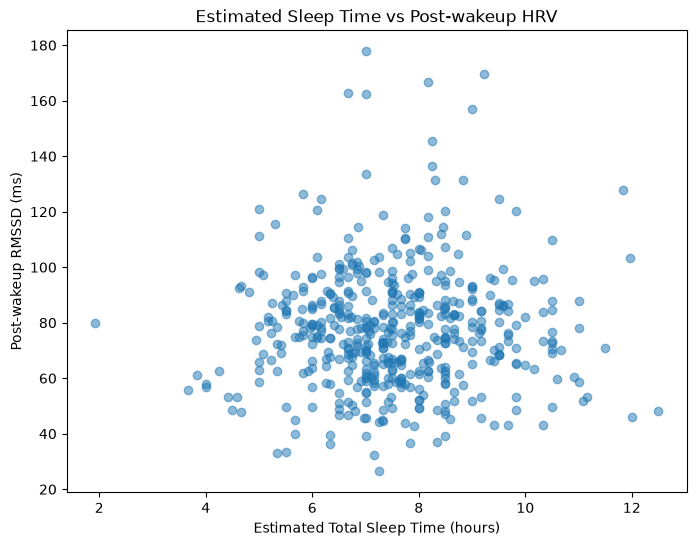

In [40]:
plot_df = analysis_df[
    [
        "actual_sleep_time",
        "post_wakeup_rmssd"
    ]
].dropna()

plt.figure(figsize=(8, 6))

plt.scatter(
    plot_df["actual_sleep_time"],
    plot_df["post_wakeup_rmssd"],
    alpha=0.5
)

plt.xlabel("Estimated Total Sleep Time (hours)")
plt.ylabel("Post-wakeup RMSSD (ms)")
plt.title("Estimated Sleep Time vs Post-wakeup HRV")

plt.show()

In [41]:
from scipy.stats import spearmanr

corr_df = analysis_df[
    ["actual_sleep_time", "post_wakeup_rmssd"]
].dropna()

rho, p_value = spearmanr(
    corr_df["actual_sleep_time"],
    corr_df["post_wakeup_rmssd"]
)

print(f"Spearman correlation: rho = {rho:.3f}")
print(f"P-value: {p_value:.4f}")

Spearman correlation: rho = 0.006
P-value: 0.8971


In [42]:
efficiency_df = analysis_df[
    ["actual_sleep_efficiency", "post_wakeup_rmssd"]
].dropna()

rho_eff, p_eff = spearmanr(
    efficiency_df["actual_sleep_efficiency"],
    efficiency_df["post_wakeup_rmssd"]
)

print(f"Spearman correlation: rho = {rho_eff:.3f}")
print(f"P-value: {p_eff:.4f}")
print(f"Observations: {len(efficiency_df)}")

Spearman correlation: rho = 0.057
P-value: 0.2076
Observations: 493


In [43]:
import statsmodels.formula.api as smf

mixed_df = analysis_df[
    [
        "userId",
        "actual_sleep_efficiency",
        "post_wakeup_rmssd"
    ]
].dropna()

mixed_model = smf.mixedlm(
    "post_wakeup_rmssd ~ actual_sleep_efficiency",
    mixed_df,
    groups=mixed_df["userId"]
)

mixed_result = mixed_model.fit()

print(mixed_result.summary())

              Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: post_wakeup_rmssd
No. Observations:   493     Method:             REML             
No. Groups:         47      Scale:              382.2960         
Min. group size:    1       Log-Likelihood:     -2183.5239       
Max. group size:    24      Converged:          Yes              
Mean group size:    10.5                                         
-----------------------------------------------------------------
                        Coef.  Std.Err.   z   P>|z| [0.025 0.975]
-----------------------------------------------------------------
Intercept               46.378   11.026 4.206 0.000 24.768 67.988
actual_sleep_efficiency 33.320   11.963 2.785 0.005  9.873 56.766
Group Var               76.595    1.357                          



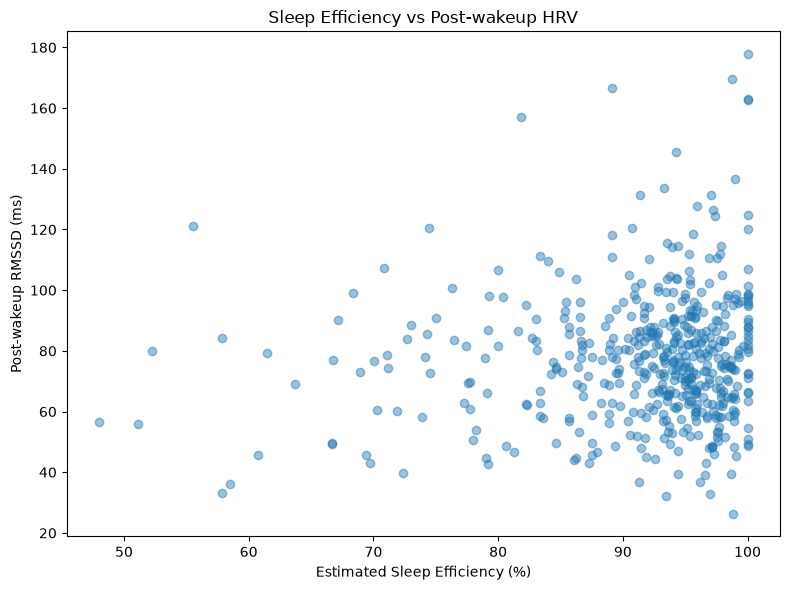

In [46]:
final_plot_df = analysis_df[
    ["actual_sleep_efficiency", "post_wakeup_rmssd"]
].dropna().copy()

final_plot_df["sleep_efficiency_pct"] = (
    final_plot_df["actual_sleep_efficiency"] * 100
)

plt.figure(figsize=(8, 6))

plt.scatter(
    final_plot_df["sleep_efficiency_pct"],
    final_plot_df["post_wakeup_rmssd"],
    alpha=0.45
)

plt.xlabel("Estimated Sleep Efficiency (%)")
plt.ylabel("Post-wakeup RMSSD (ms)")
plt.title("Sleep Efficiency vs Post-wakeup HRV")

plt.tight_layout()

plt.savefig(
    "../figures/sleep_efficiency_vs_hrv.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Conclusion

This analysis investigated the relationship between sleep and post-wakeup heart rate variability (HRV) using repeated observations from 47 participants.

Estimated total sleep time showed no meaningful monotonic association with post-wakeup RMSSD (Spearman rho = 0.006, p = 0.897).

Sleep efficiency also showed only a weak association in the unadjusted Spearman correlation (rho = 0.057, p = 0.208).

However, after accounting for repeated measurements and participant-level baseline differences using a random-intercept mixed-effects model, higher estimated sleep efficiency was associated with higher post-wakeup RMSSD (β = 33.32, p = 0.005, 95% CI: 9.87–56.77).

Because sleep efficiency was modeled from 0 to 1, this corresponds to approximately 3.33 ms higher RMSSD for each 10-percentage-point increase in estimated sleep efficiency.

These findings suggest that sleep quality may be more informative than sleep duration alone when examining short-term autonomic recovery. However, the observational design does not support causal conclusions.

### Key limitations

- Sleep measures were self-reported through sleep diaries.
- HRV was summarized from measurements collected within two hours after self-reported wake-up time.
- Two participants did not contribute valid observations after data-quality filtering.
- Potential confounders such as physical activity, stress, caffeine, alcohol, and prior-day training load were not included in the final model.
- Results describe associations and should not be interpreted as causal effects.